# Build a DEM + topographic profiles for **your volcano**

Goal: download a DEM, pin the vent to the true summit, and pull clean elevation
profiles in four directions that feed the **Eject!** ballistics model, and export a DEM
GeoTIFF large enough to bring straight into **QGIS** and overlay the hazard layers
(including the EJECT `*_eject.csv` impact data).

This notebook produces **topography only**: four radial
elevation profiles for Eject!, plus a UTM-projected DEM for QGIS.


In [1]:
import os, sys
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import pyproj
import rioxarray as rxr
import rasterio as rio
from rasterio.enums import Resampling          # <-- for bilinear reprojection
sys.path.insert(0, "/home/jovyan/shared/Libraries")
import victor
import utm

## Step 0 - settings
Everything you might change lives here.

In [3]:
VOLCANO        = ""   # Enter the GVP name
BOX_DEG        = 0.25            # half-width of the download box in degrees (~28 km here)
                                # large enough for the full ballistic hazard footprint in QGIS
DEM_SOURCE     = "COP30"         # Copernicus GLO-30: best free 30 m DEM for steep, arid terrain or SRTMGL1
FILENAME       = "volcano name_dem.tiff"
PROFILE_LEN_M  = 5000            # how far from the vent to profile, change this if you want
STEP_M         = 30              # sample spacing along the profile (~native pixel size)
BEARINGS       = {"E": 90, "N": 0, "W": 270, "S": 180}   # degrees clockwise from north
SUMMIT_SNAP_M  = 600             # search radius for the true summit pixel


## Step 1 - find the volcano

Enter the volcano name above. If an error appears, or the visualization looks odd, print the
`volcano` variable to inspect what the GVP database returned.

In [4]:
volcano = victor.search_volcano(VOLCANO)   # GVP database lookup
lat = volcano[1][0]   # vent latitude
lon = volcano[2][0]   # vent longitude
print(f"{VOLCANO}: lat={lat:.4f}, lon={lon:.4f}")

Colima: lat=19.5140, lon=-103.6200


## Step 2 - download and reproject the DEM

**bilinear** resampling instead of the default nearest-neighbor, for better elevation profile and mask nodata to `NaN`
to avoid voids.

File already exists with name DEM_19N_103W_COP30_01072026.geotiff, exiting.
Projected CRS: EPSG:32613


(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'colima_dem.tiff'}, xlabel='Easting', ylabel='Northing'>)

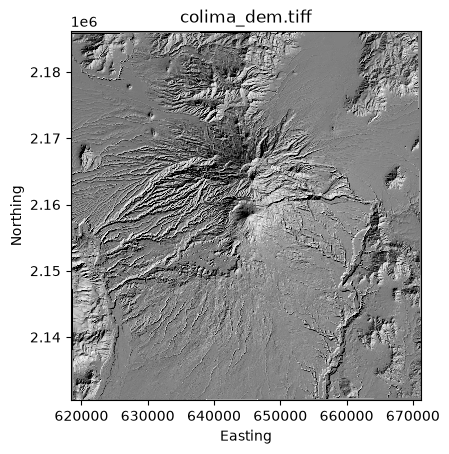

In [5]:
# Download a box around the vent: (north, south, east, west)
victor.download_dem(lat + BOX_DEG, lat - BOX_DEG, lon + BOX_DEG, lon - BOX_DEG,
                    "tiff", DEM_SOURCE, filename=FILENAME)

xds = rxr.open_rasterio(FILENAME)

# Reproject to local UTM with BILINEAR resampling (not the default nearest)
utm_crs = xds.rio.estimate_utm_crs()           # Check for your volcano
print("Projected CRS:", utm_crs)
xds_utm = xds.rio.reproject(utm_crs, resampling=Resampling.bilinear)
xds_utm.rio.to_raster(FILENAME)

# Drop the band dim, mask nodata, and make coords monotonic for interpolation
dem = xds_utm.squeeze(drop=True)
nodata = xds_utm.rio.nodata
dem = dem.where(np.isfinite(dem)) if nodata is None else dem.where(dem != nodata)
dem = dem.sortby("x").sortby("y")

victor.plot_dem(FILENAME)

## Step 3 - put the vent on the true summit

Transform the vent into the raster's
CRS (one consistent CRS) and then **snap it to the highest DEM pixel** within a small search
window.

In [6]:
# Vent in the SAME CRS as the raster (avoids zone-edge mismatches)
to_utm = pyproj.Transformer.from_crs("EPSG:4326", utm_crs, always_xy=True)
vent_e, vent_n = to_utm.transform(lon, lat)

def snap_to_summit(dem, e0, n0, r):
    """Return (easting, northing, elevation) of the highest pixel within +/- r meters."""
    m = (np.abs(dem.x - e0) <= r) & (np.abs(dem.y - n0) <= r)
    sub = dem.where(m, drop=True).fillna(-np.inf).stack(p=("y", "x"))
    k = int(sub.argmax("p").values)
    return float(sub.x[k]), float(sub.y[k]), float(sub[k])

vent_e, vent_n, vent_z = snap_to_summit(dem, vent_e, vent_n, SUMMIT_SNAP_M)
print(f"Snapped vent: E={vent_e:.0f}  N={vent_n:.0f}  elevation={vent_z:.0f} m")

Snapped vent: E=645079  N=2158133  elevation=3890 m


## Step 4 - extract an elevation profile along any bearing

<**Interpolate the DEM along a
straight transect** at any bearing with evenly spaced samples (`xarray.interp`, bilinear). This
is more accurate and works for N/E/S/W or any radial direction.

In [7]:
def extract_profile(dem, e0, n0, bearing_deg, length_m=PROFILE_LEN_M, step_m=STEP_M):
    """Sample elevation along a transect. bearing: 0=N, 90=E, 180=S, 270=W."""
    d  = np.arange(0, length_m + step_m, step_m)
    xs = e0 + d * np.sin(np.radians(bearing_deg))
    ys = n0 + d * np.cos(np.radians(bearing_deg))
    z  = dem.interp(x=xr.DataArray(xs, dims="d"),
                    y=xr.DataArray(ys, dims="d")).values
    slope = np.degrees(np.arctan2(np.diff(z), step_m))   # downslope is negative
    return d, xs, ys, z, slope

### Profile due east, as a first check

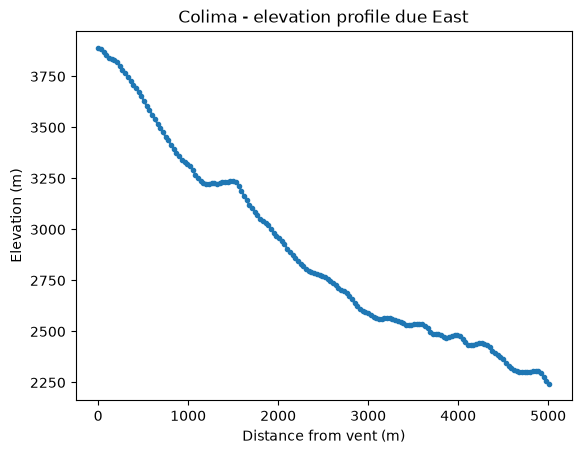

In [8]:
d, xs, ys, z, slope = extract_profile(dem, vent_e, vent_n, BEARINGS["E"])

plt.figure()
plt.plot(d, z, ".-")
plt.xlabel("Distance from vent (m)"); plt.ylabel("Elevation (m)")
plt.title(f"{VOLCANO} - elevation profile due East")
plt.show()

### Slope along the profile

<span style="color:blue">The slope now comes straight from the profile:
`arctan2(dz, step)` in degrees, with a fixed, even `step_m`, so there is no nearest-cell
stair-stepping. Negative = downhill away from the vent.</span>

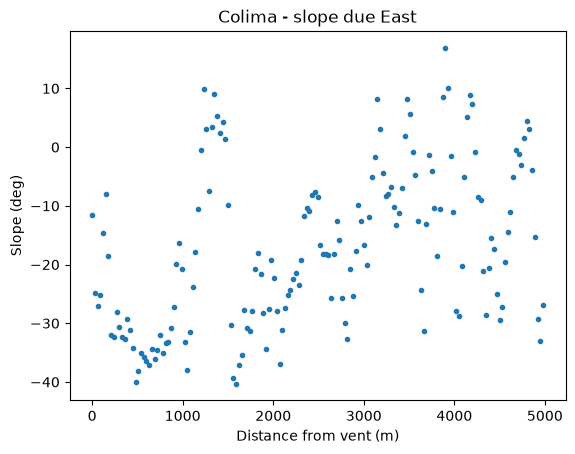

In [9]:
plt.figure()
plt.plot(d[:-1], slope, ".")
plt.xlabel("Distance from vent (m)"); plt.ylabel("Slope (deg)")
plt.title(f"{VOLCANO} - slope due East")
plt.show()

## Step 5 - do all four directions (radial)


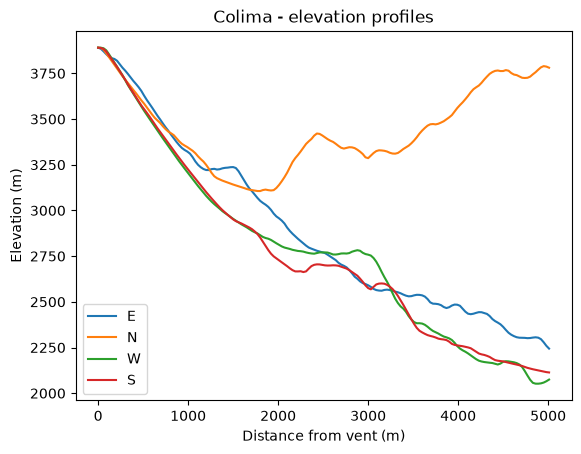

In [10]:
profiles = {}
plt.figure()
for name, brg in BEARINGS.items():
    d, xs, ys, z, slope = extract_profile(dem, vent_e, vent_n, brg)
    profiles[name] = dict(d=d, x=xs, y=ys, z=z, slope=slope)
    plt.plot(d, z, label=name)
plt.xlabel("Distance from vent (m)"); plt.ylabel("Elevation (m)")
plt.title(f"{VOLCANO} - elevation profiles"); plt.legend()
plt.show()

## Step 6 - save the profiles and the DEM for QGIS

We write the products Eject! and QGIS need from the **same** DEM, so every hazard layer
shares one surface and one CRS (UTM ??? for your volcano):

- **Eject!** format: `Dist_m, Elev_m` (one CSV per direction) for the ballistics topography step.
- A combined `colima_eject_topography.xlsx` (sheet **volcano name**) in the exact 8-column
  layout the EJECT! model reads (`x_east, topography_east, ...`).
- The UTM-projected DEM GeoTIFF (`volcano name_dem.tiff`) to drop straight into QGIS.


In [2]:
os.makedirs("profiles", exist_ok=True)

# Per-direction EJECT! CSVs (Dist_m, Elev_m)
for name, p in profiles.items():
    eject = pd.DataFrame({"Dist_m": p["d"], "Elev_m": p["z"]})
    eject.to_csv(f"profiles/{VOLCANO}_{name}_eject.csv", index=False)

# Combined workbook in the exact layout the Eject! model's distances.py reads:
#   columns: x_east, topography_east, x_north, topography_north, x_west, ... , topography_south
#   sheet name MUST match the model (here: 'Licancabur')
key = {"E": "east", "N": "north", "W": "west", "S": "south"}
topo = {}
for brg, p in profiles.items():
    topo[f"x_{key[brg]}"]           = p["d"]
    topo[f"topography_{key[brg]}"]  = p["z"]
topo_df = pd.DataFrame(topo)[[
    "x_east","topography_east","x_north","topography_north",
    "x_west","topography_west","x_south","topography_south"]]
topo_df.to_excel("Topography.xlsx", sheet_name=VOLCANO, index=False)

print("Saved Eject! profiles:", sorted(os.listdir("profiles")))
print("Saved combined topography -> Topography.xlsx (sheet '%s')" % VOLCANO)
print("Saved DEM for QGIS       -> %s (UTM, EPSG %s)" % (FILENAME, utm_crs.to_epsg()))
print("\nNote: the vent summit elevation is %.0f m -- set this as `elev` in eject.py and"
      " `vent_elevation` in distances.py / the EJECT topography notebook." % vent_z)


NameError: name 'profiles' is not defined

## Final info

This DEM and these profiles are the shared surface for the ballistic hazard map:

- **Eject!** reads `Topography.xlsx` (sheet `your volcano name`) for the four radial profiles, and the
  per-direction `*_eject.csv` files are the same data if you prefer CSVs.
- The UTM DEM GeoTIFF goes straight into **QGIS** as the basemap surface; the Eject! impact
  points (`impact_points.csv`) and your buffer/diamond hazard zones overlay on top of it.
- Everything is in one CRS (UTM ??? / EPSG:???), so all layers line up in QGIS.

Set the summit elevation printed above as `elev` in `eject.py` and `vent_elevation` in
`distances.py` (and the EJECT topography notebook) so the model's vent sits at z = 0.
